# Review 2 · Water-quality classification, Parts A and B

This notebook reruns the five Review 1 classifiers and adds the five required Review 2 classifiers on the **same water-quality dataset**, a shared stratified training sample, and a common held-out test set. It produces exactly one ten-algorithm comparison with Accuracy, weighted Precision, weighted Recall, weighted F1, and weighted one-vs-rest ROC-AUC. Source implementation: `src/classification.py`.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / 'data' / 'classification').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.classification import prepare_data, run_classification, save_outputs
sns.set_theme(style='whitegrid', palette='colorblind')
DATA_PATH = ROOT / 'data' / 'classification' / 'water_quality_classification_dataset.csv'

## 1. Data audit and EDA

Records without a class label cannot train or test a supervised classifier. Exact duplicates are removed. The same source file used in Review 1 Part A is used here. Date features add seasonal context; input columns with over 80% missingness are excluded using the training split only. Median imputation, missingness indicators, and standardization are all fitted on training data inside each model pipeline.

Audit: {'raw_rows': 80000, 'missing_targets': 12112, 'labeled_unique_rows': 67873}
Predictor matrix: (67873, 55)


,Rows
Water_Quality_Class,
Moderate,39544
Good,15644
Poor,12685


,Missing (%)
total_solids,99.064429
sulfate,98.318919
lithium,96.228250
strontium,96.024929
fluoride,95.317726
uranium,94.598736
boron,94.516229
selenium,94.286388
barium,93.968146
silica,93.943100


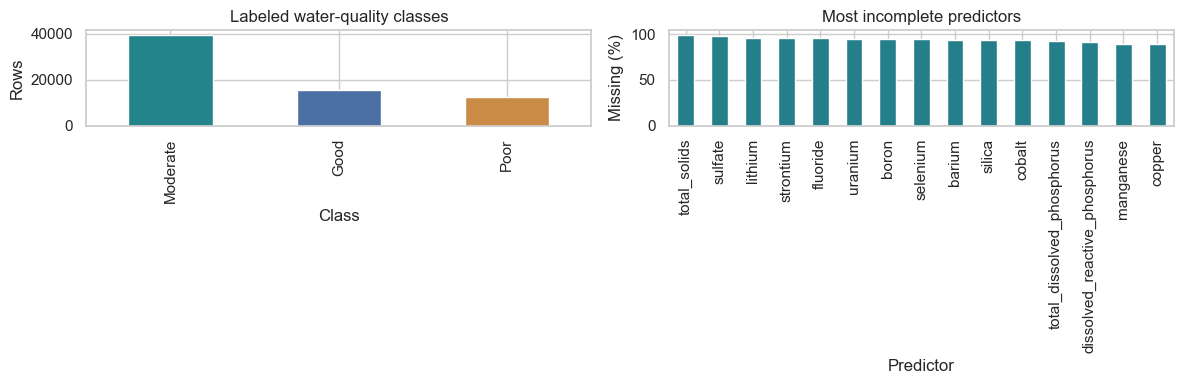

In [2]:
X, y, audit = prepare_data(DATA_PATH)
print('Audit:', audit)
print('Predictor matrix:', X.shape)
display(y.value_counts().to_frame('Rows'))
display(X.isna().mean().mul(100).sort_values(ascending=False).head(15).to_frame('Missing (%)'))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
y.value_counts().plot.bar(ax=axes[0], color=['#24848b', '#4b70a3', '#c98b46'])
axes[0].set(title='Labeled water-quality classes', xlabel='Class', ylabel='Rows')
X.isna().mean().mul(100).sort_values(ascending=False).head(15).plot.bar(ax=axes[1], color='#247f8b')
axes[1].set(title='Most incomplete predictors', xlabel='Predictor', ylabel='Missing (%)')
fig.tight_layout(); plt.show()

## 2. Train all ten required algorithms

A fixed 80:20 stratified split protects the held-out test set. For laptop runtime, every algorithm trains on the same 12,000-row stratified subset of the training partition and is evaluated on all held-out rows. This includes SVC, whose kernel and probability estimation are particularly costly. Decision Tree is tuned by three-fold grid search. The ten-model table uses its tuned version.

In [3]:
result = run_classification(DATA_PATH)
print('Training sample:', result['training_rows'], 'Held-out test rows:', result['test_rows'])
print('Classes:', result['class_names'])
print('Retained predictors:', len(result['feature_columns']))
display(result['comparison'].round(4))
assert len(result['comparison']) == 10

Training sample: 12000 Held-out test rows: 13575
Classes: ['Good', 'Moderate', 'Poor']
Retained predictors: 29


,Algorithm,Accuracy,Precision,Recall,Weighted F1,ROC-AUC
0,Random Forest,0.8855,0.8893,0.8855,0.8837,0.9680
1,Bagging,0.8788,0.8791,0.8788,0.8778,0.9607
2,Gradient Boosting,0.8770,0.8799,0.8770,0.8750,0.9603
3,Decision Tree,0.8455,0.8449,0.8455,0.8449,0.8834
4,MLP Neural Network,0.8075,0.8066,0.8075,0.8059,0.9088
5,Logistic Regression,0.7164,0.7251,0.7164,0.6946,0.8187
6,AdaBoost,0.7169,0.7499,0.7169,0.6891,0.8220
7,Support Vector Machine,0.7090,0.7226,0.7090,0.6841,0.8390
8,K-Nearest Neighbors,0.6817,0.6761,0.6817,0.6664,0.7807
9,Gaussian Naive Bayes,0.3976,0.5654,0.3976,0.3603,0.6544


## 3. Hyperparameter tuning and model selection

GridSearchCV compares Decision Tree depth and minimum leaf size. The table shows the cross-validation improvement against the untuned baseline, plus both held-out F1 scores. Random Forest and Bagging are specified in advance as the two ensemble finalists for five-fold training cross-validation; the higher mean F1 selects the saved final model. The test metrics remain a description of performance, not a fit input.

In [4]:
display(result['tuning'].round(4))
display(result['cv_table'].round(4))
print('Selected final model:', result['final_name'])

,Algorithm,Baseline 3-Fold F1,Tuned 3-Fold F1,Improvement,Baseline Test F1,Tuned Test F1,Best Parameters
0,Decision Tree,0.8319,0.8372,0.0053,0.8449,0.8449,"{'model__max_depth': 12, 'model__min_samples_l..."


,Algorithm,Mean 5-Fold Weighted F1,Std 5-Fold Weighted F1
0,Random Forest,0.8814,0.0042
1,Bagging,0.8763,0.0075


Selected final model: Random Forest


## 4. Confusion matrices and one-vs-rest ROC

A confusion matrix for each algorithm shows where its class predictions differ. The final model's probability scores produce one ROC curve per class. The consolidated table reports weighted OvR ROC-AUC so classes contribute in proportion to their test frequency.

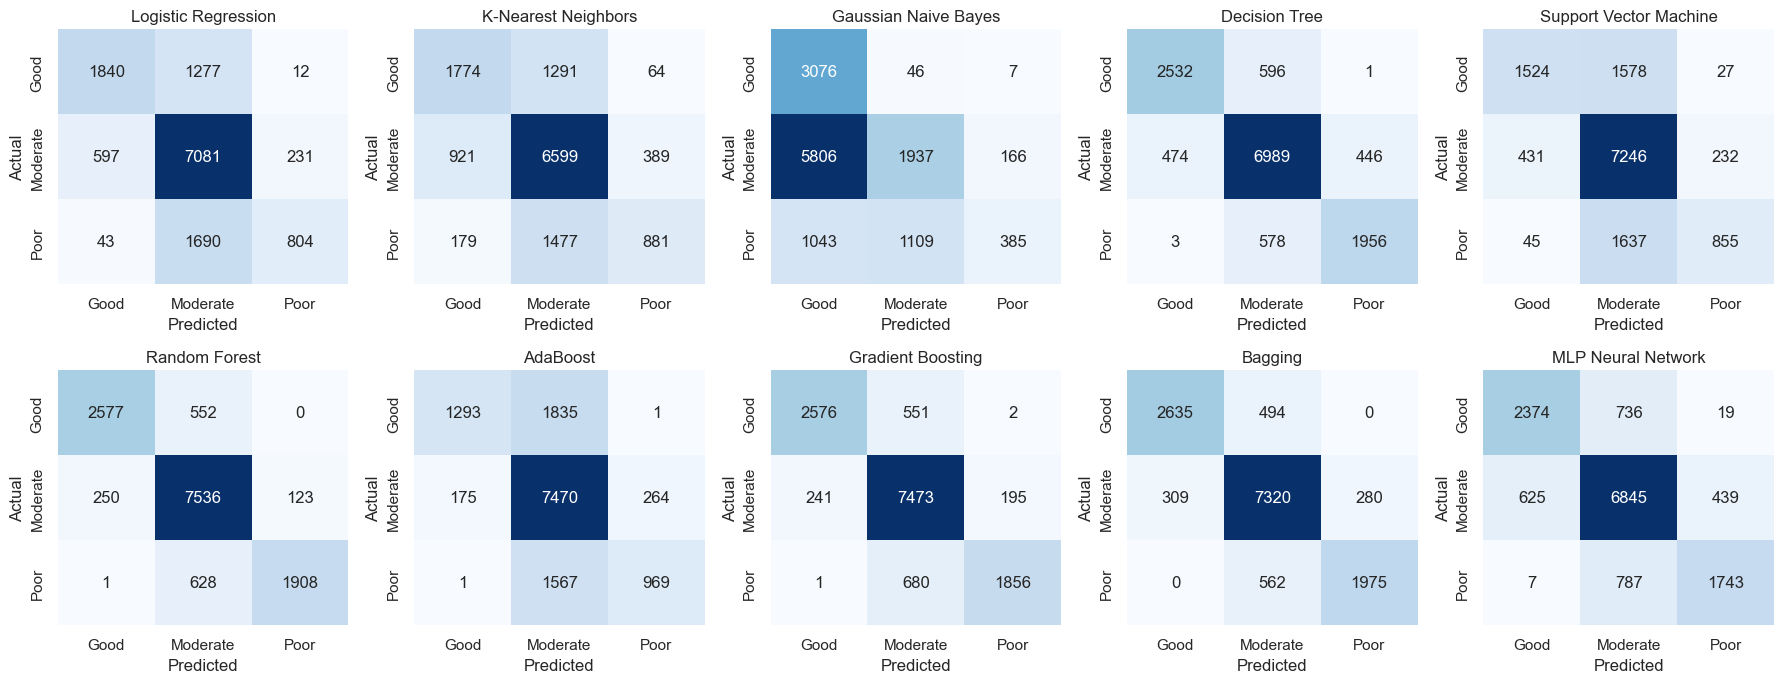

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, (name, matrix) in zip(axes.flat, result['confusion_matrices'].items()):
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=result['class_names'], yticklabels=result['class_names'], ax=ax)
    ax.set(title=name, xlabel='Predicted', ylabel='Actual')
fig.tight_layout(); plt.show()

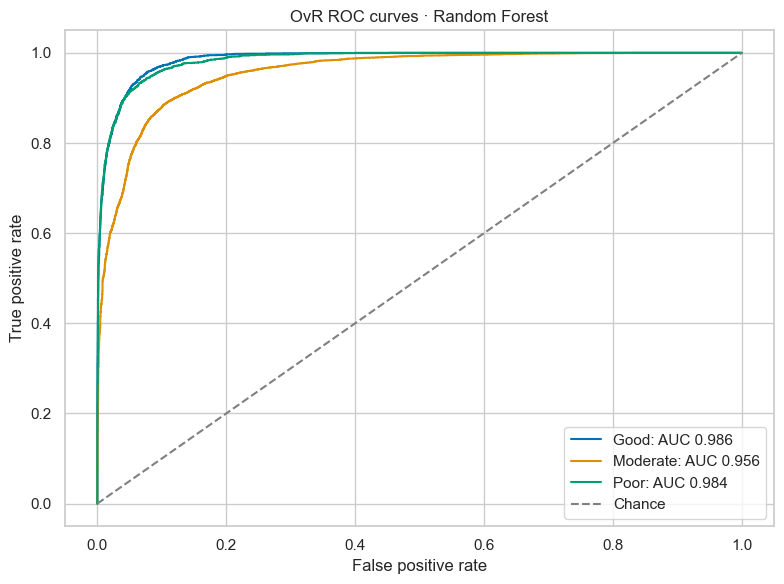

In [6]:
proba = result['final_model'].predict_proba(result['X_test'])
y_binary = label_binarize(result['y_test_code'], classes=np.arange(len(result['class_names'])))
fig, ax = plt.subplots(figsize=(8, 6))
for i, name in enumerate(result['class_names']):
    fpr, tpr, _ = roc_curve(y_binary[:, i], proba[:, i])
    ax.plot(fpr, tpr, label=f'{name}: AUC {auc(fpr, tpr):.3f}')
ax.plot([0, 1], [0, 1], '--', color='gray', label='Chance')
ax.set(title=f'OvR ROC curves · {result["final_name"]}', xlabel='False positive rate',
       ylabel='True positive rate')
ax.legend(); fig.tight_layout(); plt.show()

## 5. Export and conclusion

The table above provides the full ten-algorithm comparison required for Review 2. Weighted F1 is the main selection metric because the three classes are unequal in size. The selected model and its exact feature list are saved alongside the results. Review 1 notebooks remain in `notebooks/` as historical work; this notebook is the reproducible consolidated comparison.

In [7]:
save_outputs(result, ROOT)
print('Saved comparison, cross-validation, tuning results, and final model.')

Saved comparison, cross-validation, tuning results, and final model.
